# 4. Inside the engine

`Engine.ocr` runs a page through a fixed path: scale, orient, deskew, detect, crop, recognize, split, order. The module also exposes each step on its own, from the same C++, so this notebook takes a page down that path by hand:

1. the page at the detector's scale, as an ink map;
2. orientation, from a thumbnail;
3. detection, its four maps, and the line decoder with its thresholds changed;
4. the second detection pass for tiny text, run and merged by hand;
5. the crop rule: a line's rectangle, its crop, width buckets, light text on dark;
6. recognition and CTC decoding, and what the crop's padding does to it;
7. reading order: the order model's features, outputs and decoder, and the XY-cut.

Every model here runs through `carbon_ocr.Session`, one ONNX file on ONNX Runtime (`backend="ort"`) or on the engine's own kernels (`"native"`). The engine does a few things this notebook leaves out: deskew, the detector's head on the CPU's vectors, and splitting lines at wide gaps. So the hand-made results come out close to the engine's, but not always byte for byte.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

import carbon_ocr
import helpers
import sample_pages

plt.rcParams["figure.dpi"] = 90
SET = helpers.model_set()
pages = sample_pages.make_all("data")
engine = carbon_ocr.Engine(SET)
vocab = json.loads((SET / "rec-latin.vocab.json").read_text(encoding="utf-8"))["chars"]
print(len(vocab), "classes; class 0 is CTC's blank:", repr(vocab[0]), "then", vocab[1:12])
for name in ["orient", "det", "rec-latin", "order"]:
    s = carbon_ocr.Session(SET / f"{name}.onnx")
    print(f"{name:10} inputs {s.inputs}  outputs {s.outputs}")

800 classes; class 0 is CTC's blank: '' then [' ', '!', '"', '#', '$', '%', '&', "'", '(', ')', '*']
orient     inputs [('x', 'float32', [-1, 1, 512, 512])]  outputs [('logits', 'float32', [-1, 13])]
det        inputs [('x', 'float32', [-1, 1, -1, -1])]  outputs [('maps', 'float32', [-1, 4, -1, -1])]
rec-latin  inputs [('x', 'float32', [-1, 1, 32, -1])]  outputs [('logits', 'float32', [-1, 800, -1])]
order      inputs [('x', 'float32', [1, -1, 16])]  outputs [('successor', 'float32', [1, -1, -1]), ('same_block', 'float32', [1, -1, -1]), ('table_row', 'float32', [1, -1, -1]), ('table_col', 'float32', [1, -1, -1]), ('table_cell', 'float32', [1, -1, -1]), ('labels', 'float32', [1, -1, 13])]


## 1. The page at the detector's scale

The engine resamples each page once, its long side to 1024 px, with the crop rule's filter: an antialiased bilinear in fixed point, the same bytes as Pillow's. `carbon_ocr.resample(image, rect, w, h)` is that filter. Every model reads an *ink map*: `1 - gray / 255`, so ink is 1 and paper 0.

In [2]:
def at_scale(page, long_side=1024):
    """The page with its long side at `long_side`, and the scale from the page to it."""
    h, w = page.shape
    s = long_side / max(h, w)
    return carbon_ocr.resample(page, (0, 0, w, h), round(w * s), round(h * s)), s


def ink(gray):
    return 1.0 - gray.astype(np.float32) / 255.0


letter = carbon_ocr.load_image(pages["letter"])
small, scale = at_scale(letter)
print(f"page {letter.shape} -> detector's scale {small.shape}, scale {scale:.4f}")

page (2200, 1700) -> detector's scale (1024, 791), scale 0.4655


## 2. Orientation

`orient` reads a 512 × 512 thumbnail of the page at the detector's scale, fitted at the top left with paper around it. It gives 13 scores: 12 bins of 30° (bin k means the text is turned 30k° clockwise) and one for vertical CJK columns. The engine turns a page only by a quarter turn, for the 90°, 180° and 270° bins, and only when that bin's probability reaches the set's turn threshold. Any other answer leaves the page as it is, since a wrong turn loses the whole page.

In [3]:
orient = carbon_ocr.Session(SET / "orient.onnx")
threshold = json.loads((SET / "orient.eval.json").read_text())["turn_probability"]
print("the set's turn threshold:", threshold)


def orientation(page):
    small, _ = at_scale(page)
    h, w = small.shape
    s = 512 / max(h, w)
    thumb = carbon_ocr.resample(small, (0, 0, w, h), round(w * s), round(h * s))
    x = np.zeros((1, 1, 512, 512), np.float32)
    x[0, 0, :thumb.shape[0], :thumb.shape[1]] = ink(thumb)
    logits = orient.run([x])[0][0]
    p = np.exp(logits - logits.max())
    return p / p.sum()


for name in ["letter", "rotated", "upside-down", "skewed"]:
    p = orientation(carbon_ocr.load_image(pages[name]))
    k = int(p.argmax())
    turn = 30 * k if k in (3, 6, 9) and p[k] >= threshold else 0
    print(f"{name:12} best bin {k:2} ({30 * k:3}°, p {p[k]:.3f}) -> turn {turn:3}°   "
          f"the engine's rotation: {engine.ocr([carbon_ocr.load_image(pages[name])])[0]['rotation']}")

the set's turn threshold: 0.65
letter       best bin  0 (  0°, p 0.783) -> turn   0°   the engine's rotation: 0


rotated      best bin  3 ( 90°, p 0.953) -> turn  90°   the engine's rotation: 90


upside-down  best bin  6 (180°, p 0.751) -> turn 180°   the engine's rotation: 180
skewed       best bin  0 (  0°, p 0.773) -> turn   0°   the engine's rotation: 0


The skewed page's 2.5° is below a bin's 30°, so it stays in bin 0. The engine levels such a skew without a model: it projects the page's ink onto its rows at angles up to ±5° and takes the angle where the lines' ink falls into the fewest rows.

## 3. Detection

`det` reads the upright page's ink map, padded with paper to a multiple of 32, and gives four maps at stride 2:

| map | what |
|---|---|
| core | a logit: the line's core band, the middle 40% of its height, its ends shortened by 0.15 of its height, so neighbouring lines' bands never touch |
| top | at a core pixel, the distance in input pixels up to the line's top |
| bottom | the same, down to the line's bottom |
| picture | a logit: inside a picture |

maps: (4, 512, 400)


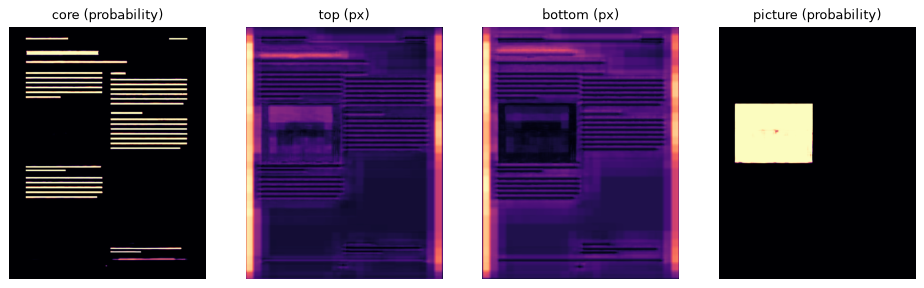

In [4]:
det = carbon_ocr.Session(SET / "det.onnx", threads=4)


def detect(page, long_side=1024):
    """The detector's maps [4, h/2, w/2] for a page at `long_side`, and the scale from the page to its input."""
    small, s = at_scale(page, long_side)
    h, w = small.shape
    x = np.zeros((1, 1, -(-h // 32) * 32, -(-w // 32) * 32), np.float32)  # padded with paper (ink 0)
    x[0, 0, :h, :w] = ink(small)
    return det.run([x])[0][0], s


columns = carbon_ocr.load_image(pages["columns"])
maps, s = detect(columns)
sigmoid = lambda v: 1 / (1 + np.exp(-v))
fig, axes = plt.subplots(1, 4, figsize=(13, 4.6))
for ax, (title, m) in zip(axes, [("core (probability)", sigmoid(maps[0])), ("top (px)", maps[1]),
                                 ("bottom (px)", maps[2]), ("picture (probability)", sigmoid(maps[3]))]):
    ax.imshow(m, cmap="magma")
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
print("maps:", maps.shape)

`carbon_ocr.decode_det(maps, scale)` is the engine's line decoder, in C++. It thresholds the core and picture maps at a probability of 0.5 and takes the core band's connected components. A line's top and bottom are the 5% and 95% quantiles of its band pixels' edges, and its ends lie 0.15 of its height beyond its band's. It gives each line and picture as `((x0, y0, x1, y1), score, pixels)`, in the input's pixels times `scale`: `1 / s` brings them back to the page's.

36 lines and 1 pictures; the engine's page: 44 lines after splitting and the gate
  ( 140.3   84.2  521.4  122.5)  score 0.93  282 map pixels
  (1391.5   88.3 1560.4  121.4)  score 0.98  111 map pixels
  ( 137.0  183.2  795.4  272.4)  score 0.97  1164 map pixels
  ( 138.6  281.8 1038.7  331.4)  score 0.89  980 map pixels


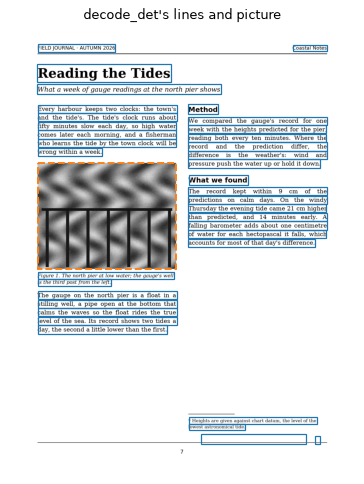

In [5]:
lines, pictures = carbon_ocr.decode_det(maps, scale=1 / s)
print(len(lines), "lines and", len(pictures), "pictures; the engine's page:",
      len(engine.ocr([columns])[0]["lines"]), "lines after splitting and the gate")
for box, score, pixels in lines[:4]:
    print(f"  ({box[0]:6.1f} {box[1]:6.1f} {box[2]:6.1f} {box[3]:6.1f})  score {score:.2f}  {pixels} map pixels")
helpers.show(columns, [b for b, _, _ in lines], [b for b, _, _ in pictures], title="decode_det's lines and picture", width=5);

The decoder's numbers are all arguments. A lower `core_threshold` widens every band, so bands that nearly touch can merge into one line; a higher one narrows them, and faint lines drop out. `min_core_pixels` is the smallest band that counts as a line, and `min_picture_pixels` the smallest picture. Each setting below is compared with the defaults' lines, the lines it loses or gains named by the engine's reading of them (with the gate off, so the rules have names too).

In [6]:
named = carbon_ocr.Engine(SET, gate=False, justified=True, single_pixel=0.5).ocr([columns])[0]["lines"]


def name_of(box):
    best = max(named, key=lambda line: helpers.iou(line["box"], box))
    return best["text"][:24] if helpers.iou(best["box"], box) > 0.3 else "(no line of the engine's)"


default = [b for b, _, _ in lines]
for options in [dict(core_threshold=0.2), dict(core_threshold=0.8), dict(min_core_pixels=1),
                dict(min_core_pixels=40), dict(picture_threshold=0.9)]:
    l, p = carbon_ocr.decode_det(maps, scale=1 / s, **options)
    boxes_now = [b for b, _, _ in l]
    lost = [name_of(b) for b in default if max(helpers.iou(b, c) for c in boxes_now) < 0.5]
    gained = [name_of(b) for b in boxes_now if max(helpers.iou(b, c) for c in default) < 0.5]
    print(f"{str(options):28} {len(l):3} lines, {len(p)} picture   lost {lost}  gained {gained}")

{'core_threshold': 0.2}       36 lines, 1 picture   lost ['___']  gained ['7']
{'core_threshold': 0.8}       34 lines, 1 picture   lost ['__________________', '___']  gained []
{'min_core_pixels': 1}        37 lines, 1 picture   lost []  gained ['7']
{'min_core_pixels': 40}       35 lines, 1 picture   lost ['___']  gained []
{'picture_threshold': 0.9}    36 lines, 1 picture   lost []  gained []


On this page the text's core bands are clear-cut. At a threshold of 0.2 and at 0.8, every line of text is found as at 0.5, and only the rules come and go (the gate would drop them anyway); 0.2 also widens the page number's faint band at the foot of the page enough to keep it. With `min_core_pixels=1` the decoder keeps the page number at the foot of the page, a band of one map pixel, as the engine does with `single_pixel` (notebook 2). A larger minimum loses the smallest band first, the short rule.

## 4. The second pass, by hand

`takes_second_pass(lines)` is the engine's test: the median height of `decode_det`'s lines at the detector's scale under 9 px (`DET_SECOND_PASS_BELOW`). Then the page is detected again at twice the scale (`DET_SECOND_PASS_SCALE`), and `merge_passes` pairs the two passes' lines: boxes that overlap by more than 0.5 IoU (`DET_MERGE_IOU`) are one line, kept from the second pass where it is tiny at the first pass's scale. The newspaper's page takes it.

In [7]:
print("second pass below", carbon_ocr.DET_SECOND_PASS_BELOW, "px, at", carbon_ocr.DET_SECOND_PASS_SCALE,
      "times the scale, merged above", carbon_ocr.DET_MERGE_IOU, "IoU")
news = carbon_ocr.load_image(pages["newspaper"])
maps1, s1 = detect(news)
first = carbon_ocr.decode_det(maps1)  # at the detector's scale, where the test is made
heights = [b[3] - b[1] for b, _, _ in first[0]]
print(f"first pass: {len(first[0])} lines, median height {np.median(heights):.1f} px -> second pass:",
      carbon_ocr.takes_second_pass(first[0]))
maps2, s2 = detect(news, long_side=2048)
second = carbon_ocr.decode_det(maps2, scale=s1 / s2)  # in the first pass's pixels
merged = carbon_ocr.merge_passes(first, second)
print(f"second pass: {len(second[0])} lines; merged: {len(merged[0])} lines")

# how well each pass's boxes fit the lines as drawn: each true line's best overlap (IoU) with a box
truth_boxes = [t["box"] for t in sample_pages.truth(pages["newspaper"])["lines"]]
for label, ls in [("first pass", first[0]), ("merged", merged[0])]:
    on_page = [(b[0] / s1, b[1] / s1, b[2] / s1, b[3] / s1) for b, _, _ in ls]
    fit = [max(helpers.iou(t, b) for b in on_page) for t in truth_boxes]
    print(f"{label:10}: mean best IoU with the true lines {np.mean(fit):.3f}, lines under 0.5: "
          f"{sum(f < 0.5 for f in fit)} of {len(fit)}")

second pass below 9.0 px, at 2.0 times the scale, merged above 0.5 IoU
first pass: 840 lines, median height 7.8 px -> second pass: True
second pass: 822 lines; merged: 819 lines


first pass: mean best IoU with the true lines 0.590, lines under 0.5: 114 of 807


merged    : mean best IoU with the true lines 0.683, lines under 0.5: 0 of 807


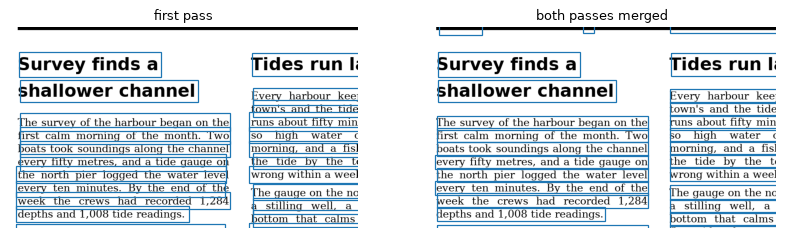

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
x0, y0, x1, y1 = 100, 300, 900, 760  # a part of the page, in its pixels
part = news[y0:y1, x0:x1]
for ax, (title, ls) in zip(axes, [("first pass", first[0]), ("both passes merged", merged[0])]):
    boxes = [(b[0] / s1 - x0, b[1] / s1 - y0, b[2] / s1 - x0, b[3] / s1 - y0) for b, _, _ in ls]
    helpers.show(part, [b for b in boxes if b[2] > 0 and b[0] < x1 - x0 and b[3] > 0 and b[1] < y1 - y0],
                 ax=ax, title=title)

At the first pass's scale the newspaper's lines are a few map pixels high, and 114 of its 807 lines get no box that overlaps them by half. With the second pass merged in, every line has one, and the boxes fit the lines better on the whole (a mean IoU of 0.68, against 0.59). The engine runs that pass in strips of about a first pass's pixels, so a worker's detector never holds much more memory than it does for an ordinary page.

## 5. The crop rule

The recognizer reads each line as a crop 32 px high. `crop_region(box)` gives the page rectangle a box's crop takes: the box gets 0.2 of its height of padding above and below and 0.3 at each end, is scaled to 32 px, then widened into the page to a multiple of 8. `crop(page, box)` makes the crop, `ctc_frames(box)` gives the recognizer's frames for it (one every 4 px), and `width_bucket(width)` gives the batch width the engine runs it at.

the crop rule: height 32 | width step 8 | a frame every 4 px | padding 0.2 and 0.3 of the height
box (  156   162  1017   238) -> rect (  132   147  1041   254), crop (32, 272), 68 frames, bucket 272 px
box (  160   246   871   293) -> rect (  143   237   888   303), crop (32, 360), 90 frames, bucket 360 px
box (  161   344  1480   387) -> rect (  142   335  1499   396), crop (32, 712), 178 frames, bucket 808 px
box (  161   390  1536   433) -> rect (  146   382  1551   441), crop (32, 752), 188 frames, bucket 808 px


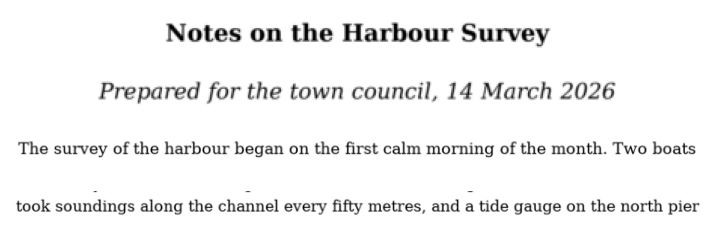

In [9]:
print("the crop rule: height", carbon_ocr.HEIGHT, "| width step", carbon_ocr.WIDTH_STEP, "| a frame every",
      carbon_ocr.FRAME, "px | padding", carbon_ocr.PAD_V, "and", carbon_ocr.PAD_H, "of the height")
maps, s = detect(letter)
lines, _ = carbon_ocr.decode_det(maps, scale=1 / s)
boxes = [b for b, _, _ in lines]
fig, axes = plt.subplots(4, 1, figsize=(10, 3.2))
for ax, box in zip(axes, boxes[:4]):
    rect, width = carbon_ocr.crop_region(box)
    c = carbon_ocr.crop(letter, box)
    print(f"box ({box[0]:5.0f} {box[1]:5.0f} {box[2]:5.0f} {box[3]:5.0f}) -> rect ({rect[0]:5.0f} {rect[1]:5.0f} "
          f"{rect[2]:5.0f} {rect[3]:5.0f}), crop {c.shape}, {carbon_ocr.ctc_frames(box)} frames, "
          f"bucket {carbon_ocr.width_bucket(width)} px")
    ax.imshow(c, cmap="gray", vmin=0, vmax=255)
    ax.set_axis_off()

The width buckets are 32, 48, 64, 88, 120 and so on, each at most 1.3 times the one before, up to 2048 px. Lines are batched by bucket, so a run meets few shapes and the padding stays small. `crop_lines(page, boxes, out_width)` crops many lines at once into a batch of one width, each padded with its own ground (`ground(crop)`). It flips any crop of light text on a dark ground (`light_on_dark`), so the recognizer always reads dark ink on light paper.

line at y   154: light on dark True, ground 20
line at y   417: light on dark True, ground 70
line at y   554: light on dark False, ground 255
line at y   600: light on dark False, ground 255
batch (4, 32, 808) crop widths [192, 392, 688, 640]


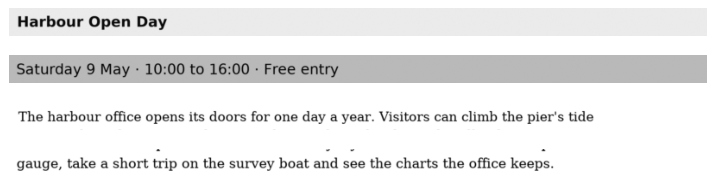

In [10]:
banner = carbon_ocr.load_image(pages["banner"])
bmaps, bs = detect(banner)
blines, _ = carbon_ocr.decode_det(bmaps, scale=1 / bs)
bboxes = np.array([b for b, _, _ in blines[:4]], np.float64)
for box in bboxes:
    c = carbon_ocr.crop(banner, tuple(box))
    print(f"line at y {box[1]:5.0f}: light on dark {carbon_ocr.light_on_dark(c)}, ground {carbon_ocr.ground(c)}")
widths = [carbon_ocr.crop_region(tuple(b))[1] for b in bboxes]
batch, crop_widths = carbon_ocr.crop_lines(banner, bboxes, carbon_ocr.width_bucket(max(widths)))
print("batch", batch.shape, "crop widths", crop_widths)
fig, axes = plt.subplots(len(batch), 1, figsize=(10, 2.6))
for ax, c in zip(axes, batch):
    ax.imshow(c, cmap="gray", vmin=0, vmax=255)
    ax.set_axis_off()

The banner's title and the grey box's line come out flipped, as dark text on light paper, padded to the batch's width.

## 6. Recognition and CTC decoding

`rec-latin` reads a batch of ink maps `[n, 1, 32, W]` and gives logits `[n, classes, W/4]`: a score for each of its 800 classes every 4 px, class 0 being CTC's blank. `ctc_greedy(logits, lengths)` decodes them as the engine does. It takes each frame's best class, drops blanks and collapses repeats, and gives each line its class ids, the frame each character starts at, and each character's probability. `lengths` holds each line's own frames, so a crop never reads its batch's padding.

In [11]:
rec = carbon_ocr.Session(SET / "rec-latin.onnx")


def recognize(page, boxes, **rule):
    """Each box's text and confidence, the boxes batched by the engine's width buckets."""
    out = [None] * len(boxes)
    buckets = {}
    for i, box in enumerate(boxes):
        buckets.setdefault(carbon_ocr.width_bucket(carbon_ocr.crop_region(box, **rule)[1]), []).append(i)
    for width, idx in sorted(buckets.items()):
        crops, _ = carbon_ocr.crop_lines(page, np.array([boxes[i] for i in idx], np.float64), width, **rule)
        logits = rec.run([ink(crops)[:, None]])[0]
        lengths = np.array([carbon_ocr.ctc_frames(boxes[i], **rule) for i in idx], np.int32)
        for i, (ids, frames, probs) in zip(idx, carbon_ocr.ctc_greedy(logits, lengths)):
            text = "".join(vocab[c] for c in ids)
            chars = [p for c, p in zip(ids, probs) if vocab[c] != " "]
            out[i] = (text, float(np.mean(chars)) if chars else 0.0)
    return out


by_hand = recognize(letter, boxes)
by_engine = [line["text"] for line in engine.ocr([letter])[0]["lines"]]
same = sum(t == e for (t, _), e in zip(by_hand, by_engine))
print(f"{same} of {len(boxes)} lines read as the engine reads them\n")
for text, conf in by_hand[:6]:
    print(f"{conf:.3f}  {text}")

21 of 21 lines read as the engine reads them

1.000  Notes on the Harbour Survey
1.000  Prepared for the town council, 14 March 2026
1.000  The survey of the harbour began on the first calm morning of the month. Two boats
1.000  took soundings along the channel every fifty metres, and a tide gauge on the north pier
1.000  logged the water level every ten minutes. By the end of the week the crews had
1.000  recorded 1,284 depths and 1,008 tide readings.


····N··o·t·e··s  oo·n·  t·h··e   H··a··r·b··o·u··r  ·S·u··r·v·e··y··


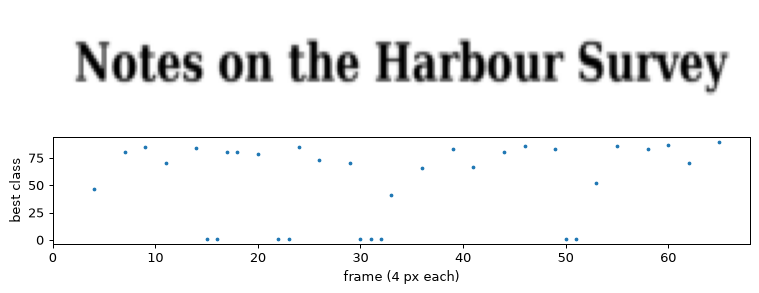

In [12]:
c = carbon_ocr.crop_lines(letter, np.array([boxes[0]], np.float64), carbon_ocr.width_bucket(carbon_ocr.crop_region(boxes[0])[1]))[0]
logits = rec.run([ink(c)[:, None]])[0][0]
n = carbon_ocr.ctc_frames(boxes[0])
best = logits[:, :n].argmax(0)
fig, axes = plt.subplots(2, 1, figsize=(10, 3.4), sharex=True)
axes[0].imshow(c[0], cmap="gray", vmin=0, vmax=255, extent=(0, n, 32, 0), aspect="auto")
axes[0].set_axis_off()
axes[1].plot(np.where(best == 0, np.nan, best), ".", ms=4)
axes[1].set_ylabel("best class")
axes[1].set_xlabel("frame (4 px each)")
print("".join(vocab[k] if k else "·" for k in best))

Each frame's best class, the blanks shown as `·`: a character takes a frame or two, and blanks fill the gaps between them. That is all CTC's greedy decoding reads.

The recognizer learned on crops made by its own crop rule (32 px high, 0.2 and 0.3 of padding), and `crop_region`, `crop_lines` and `ctc_frames` take the rule's numbers as arguments. Less padding above and below makes the text larger in the crop, and more makes it smaller; none at the ends brings the first and last letters to the crop's edges:

In [13]:
truth = [t["text"] for t in sample_pages.truth(pages["letter"])["lines"]]
for pad_v, pad_h in [(0.2, 0.3), (0.05, 0.3), (0.5, 0.3), (0.2, 0.0)]:
    read = [t for t, _ in recognize(letter, boxes, pad_v=pad_v, pad_h=pad_h)]
    e = carbon_ocr.text_errors(truth, read) if len(read) == len(truth) else None
    cer = e[:, 0].sum() / e[:, 1].sum() if e is not None else float("nan")
    print(f"pad_v {pad_v:4}, pad_h {pad_h}: CER {cer:6.2%}   first line: {read[0]!r}")

pad_v  0.2, pad_h 0.3: CER  0.00%   first line: 'Notes on the Harbour Survey'

pad_v 0.05, pad_h 0.3: CER  0.00%   first line: 'Notes on the Harbour Survey'
pad_v  0.5, pad_h 0.3: CER  0.15%   first line: 'Notes on the Harbour Survey'


pad_v  0.2, pad_h 0.0: CER  0.22%   first line: 'Notes on the Harbour Survey'


On this clean page the recognizer still reads every line with less padding above and below. With more, or with none at the ends, it misreads a few characters. The engine always crops by the rule its recognizer was trained with, which a recognizer's file can carry (`carbon.crop.height`, `pad_v`, `pad_h`).

## 7. Reading order

`order` reads 16 features for each line (`order_features`: its box, centre, width, height and aspect against the page, and text cues such as a list marker or a sentence's end). It gives pairwise scores for five relations, and one of 13 block labels for each line. `decode_order` turns them into an order. It builds a greedy chain over the successor probabilities, then makes up to 4 repair sweeps. Blocks are runs of lines whose neighbours are in the same block with a probability of at least `join`. `sure` is the chain's mean link probability, and under `min_sure` the decoder falls back to the XY-cut's order (`fallback`). Here it runs on the two-column page's lines as the engine found them.

In [14]:
page = carbon_ocr.Engine(SET, justified=True).ocr([columns])[0]
line_boxes = np.array([l["box"] for l in page["lines"]], np.float64)
texts = [l["text"] for l in page["lines"]]
features = carbon_ocr.order_features(line_boxes, texts, page["width"], page["height"])
print("features:", features.shape, "| the labels:", carbon_ocr.BLOCK_LABELS[:7], "...")
order = carbon_ocr.Session(SET / "order.onnx")
outputs = dict(zip([name for name, _, _ in order.outputs], order.run([features[None]])))
print({k: v.shape for k, v in outputs.items()})


def decoded(**rule):
    return carbon_ocr.decode_order(*(outputs[k][0] for k in ["successor", "same_block", "table_row", "table_col",
                                                            "table_cell", "labels"]), line_boxes, **rule)


d = decoded()
print(f"sure {d['sure']:.3f}, fallback {d['fallback']}, {len(d['blocks'])} blocks")
for label, confidence, lines, cells in d["blocks"]:
    print(f"   {label:15} {confidence:.2f}  {texts[lines[0]][:50]}")

features: (34, 16) | the labels: ['Text', 'Section-Header', 'Page-Header', 'Page-Footer', 'List-Group', 'Table', 'Caption'] ...
{'successor': (1, 35, 35), 'same_block': (1, 34, 34), 'table_row': (1, 34, 34), 'table_col': (1, 34, 34), 'table_cell': (1, 34, 34), 'labels': (1, 34, 13)}
sure 0.912, fallback False, 11 blocks
   Page-Header     1.00  Coastal Notes
   Page-Header     1.00  FIELD JOURNAL - AUTUMN 2026
   Section-Header  0.99  Reading the Tides
   Text            0.98  What a week of gauge readings at the north pier sh
   Caption         0.98  Figure 1. The north pier at low water; the gauge's
   Text            0.98  The gauge on the north pier is a float in a
   Section-Header  0.97  Method
   Text            0.99  We compared the gauge's record for one
   Section-Header  0.86  What we found
   Text            0.99  The record kept within 9 cm of the
   Caption         0.79  * Heights are given against chart datum, the level


The model's own order reads column 1 to its end, then column 2, as notebook 2 found with `block_order="model"`. `join` decides how readily lines join a block, and `min_sure` when the model is trusted at all:

In [15]:
for rule in [dict(join=0.2), dict(join=0.9), dict(min_sure=0.999)]:
    d = decoded(**rule)
    print(f"{rule}: {len(d['blocks'])} blocks, fallback {d['fallback']}, first lines in order:",
          [texts[i][:14] for i in d["order"][:6]])
xy = carbon_ocr.reading_order(line_boxes)
print("\nthe XY-cut's order:", [texts[i][:14] for i in xy[:12]])

{'join': 0.2}: 9 blocks, fallback False, first lines in order: ['Coastal Notes', 'FIELD JOURNAL ', 'Reading the Ti', 'What a week of', 'Every harbour ', "and the tide's"]
{'join': 0.9}: 14 blocks, fallback False, first lines in order: ['Coastal Notes', 'FIELD JOURNAL ', 'Reading the Ti', 'What a week of', 'Every harbour ', "and the tide's"]
{'min_sure': 0.999}: 11 blocks, fallback True, first lines in order: ['FIELD JOURNAL ', 'Coastal Notes', 'Reading the Ti', 'What a week of', 'Every harbour ', "and the tide's"]

the XY-cut's order: ['FIELD JOURNAL ', 'Coastal Notes', 'Reading the Ti', 'What a week of', 'Every harbour ', "and the tide's", 'fifty minutes ', 'comes later ea', 'who learns the', 'wrong within a', 'Method', 'We compared th']


A higher `join` breaks the page into more blocks, and a lower one merges them. A `min_sure` above the chain's mean link probability sends the page to the XY-cut. The XY-cut alone cuts the two-column page at its widest gaps, again and again. The first cut runs across the whole page below the end of column 2's text, so the XY-cut reads column 2 before the lower half of column 1. Ordering the model's blocks by geometry (the engine's default) does the same.

## What the engine adds

The engine runs these same steps, and a few more:

- It turns the page upright, then levels it.
- It runs the detector's head on the CPU's vectors, in row bands.
- It cuts the second pass into strips.
- It spreads each page's lines over the idle cores.
- It splits lines at wide gaps and drops lines that are not text.
- It orders the blocks by their geometry and lays tables out with their spans.

`Engine` is the fast way to read pages. The functions here are for seeing, checking or changing one step.